# Computer Vision — Assignment 1
### Step-by-step Colab implementation

This notebook solves **Q1–Q4** of the supplied Computer Vision Assignment 1.

**Design choices**
- Images are converted to grayscale where required.
- Important intermediate results are displayed rather than hidden inside functions.
- At least one interpolation/filter/derivative operation is implemented manually.
- Quantitative comparisons use **MSE** and **PSNR** where requested.
- Parameters are kept explicit so they can be changed and re-run easily.


## 0. Setup

The assignment asks for image resizing/interpolation, smoothing, hybrid images, and edge detection. It also explicitly asks for intermediate/final outputs and original implementations for selected operations.

In [36]:
# Colab setup
!pip -q install scikit-image opencv-python-headless

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import time
import math
from skimage import data, color, transform, img_as_float
from scipy import ndimage

np.random.seed(42)

plt.rcParams["figure.figsize"] = (14, 8)
plt.rcParams["image.cmap"] = "gray"

def show_images(images, titles, cols=4, figsize=None, vmin=0, vmax=1):
    n = len(images)
    rows = int(np.ceil(n / cols))
    if figsize is None:
        figsize = (4*cols, 3.5*rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, im, title in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def mse(a, b):
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    return np.mean((a-b)**2)

def psnr(a, b, data_range=1.0):
    e = mse(a, b)
    return np.inf if e == 0 else 10*np.log10((data_range**2)/e)

def normalize_for_display(x):
    x = np.asarray(x, dtype=np.float64)
    lo, hi = np.percentile(x, [1, 99])
    return np.clip((x-lo)/(hi-lo+1e-12), 0, 1)



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\sidharth\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Q1. Image Resizing, Interpolation, and Edge Analysis

The assignment specifies a **512×512 grayscale image**, downsampling to 256×256 and 128×128, reconstructing to 512×512 using nearest-neighbour, bilinear and bicubic interpolation, then comparing MSE, PSNR, error maps and edge preservation. 

We use `skimage.data.camera()`, which is a standard 512×512 grayscale test image.

Original shape: (512, 512)


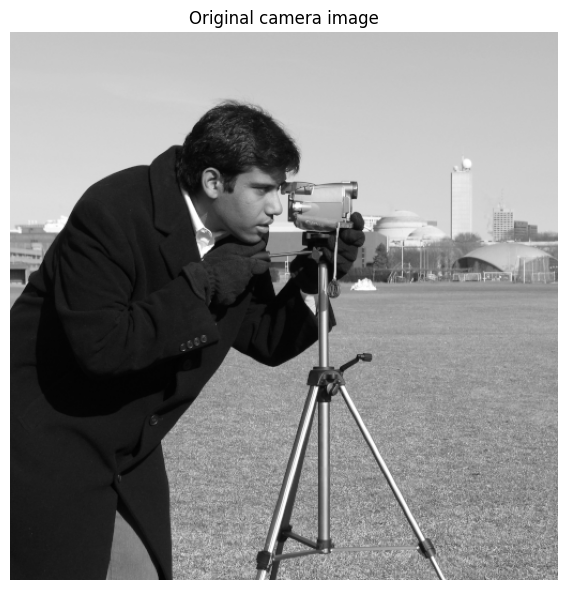

In [37]:
# Q1. Original 512x512 image
original = img_as_float(data.camera())

print("Original shape:", original.shape)
show_images([original], ["Original camera image"], cols=1, figsize=(6,6))


256x256: (256, 256)
128x128: (128, 128)


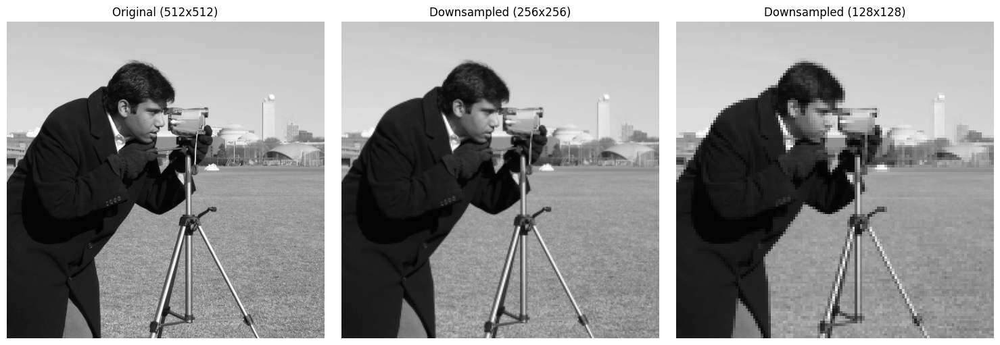

In [38]:
# Downsample to 256x256 and 128x128
img_256 = cv2.resize(original, (256, 256), interpolation=cv2.INTER_AREA)
img_128 = cv2.resize(original, (128, 128), interpolation=cv2.INTER_AREA)

print("256x256:", img_256.shape)
print("128x128:", img_128.shape)
show_images([original, img_256, img_128],
            ["Original (512x512)", "Downsampled (256x256)", "Downsampled (128x128)"],
            cols=3, figsize=(15,5))


### Manual nearest-neighbour interpolation

This function is deliberately written without calling an image-resizing routine. It directly maps each output pixel to the nearest source pixel. This satisfies the assignment's requirement that at least one interpolation method be implemented without a built-in resizing function.

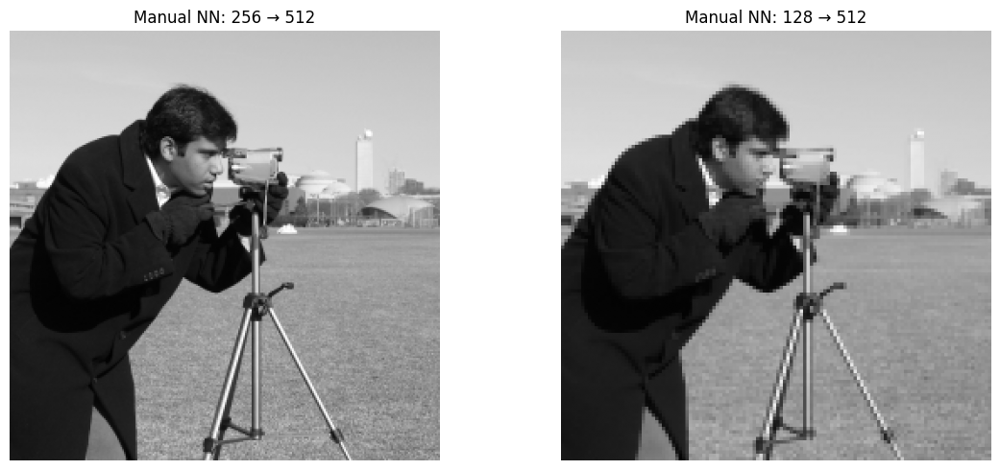

In [39]:
def nearest_resize_manual(img, out_h, out_w):
    h, w = img.shape[:2]
    row_map = np.floor(np.arange(out_h) * h / out_h).astype(int)
    col_map = np.floor(np.arange(out_w) * w / out_w).astype(int)
    row_map = np.clip(row_map, 0, h-1)
    col_map = np.clip(col_map, 0, w-1)
    return img[row_map[:, None], col_map[None, :]]

# Quick verification
nn_256_manual = nearest_resize_manual(img_256, 512, 512)
nn_128_manual = nearest_resize_manual(img_128, 512, 512)

show_images(
    [nn_256_manual, nn_128_manual],
    ["Manual NN: 256 → 512", "Manual NN: 128 → 512"],
    cols=2, figsize=(12,5)
)


### Bilinear and bicubic reconstruction

For comparison, OpenCV is used for bilinear and bicubic interpolation. The nearest-neighbour result remains the manually implemented version above.

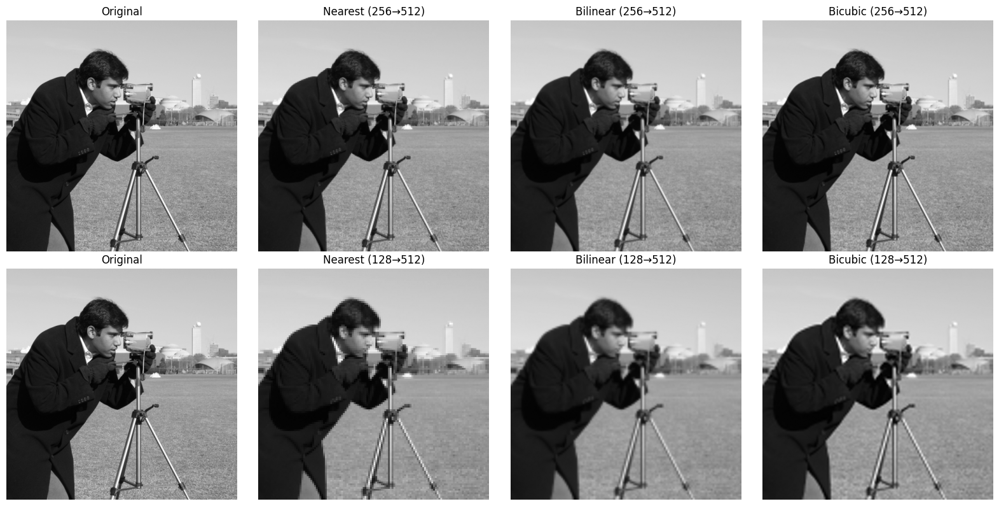

In [40]:
def reconstruct_all(img_small):
    return {
        "Nearest": nearest_resize_manual(img_small, 512, 512),
        "Bilinear": cv2.resize(img_small, (512,512), interpolation=cv2.INTER_LINEAR),
        "Bicubic": cv2.resize(img_small, (512,512), interpolation=cv2.INTER_CUBIC)
    }

rec_256 = reconstruct_all(img_256)
rec_128 = reconstruct_all(img_128)

show_images(
    [original, rec_256["Nearest"], rec_256["Bilinear"], rec_256["Bicubic"],
     original, rec_128["Nearest"], rec_128["Bilinear"], rec_128["Bicubic"]],
    ["Original"] + [f"{k} (256→512)" for k in rec_256] +
    ["Original"] + [f"{k} (128→512)" for k in rec_128],
    cols=4, figsize=(16,8)
)


In [41]:
# Quantitative comparison: MSE and PSNR
rows = []
for factor, recs in [("256→512", rec_256), ("128→512", rec_128)]:
    for method, img in recs.items():
        rows.append({
            "Downsample → Reconstruction": factor,
            "Interpolation": method,
            "MSE": mse(original, img),
            "PSNR (dB)": psnr(original, img)
        })

q1_metrics = pd.DataFrame(rows)
display(q1_metrics.round(6))


,Downsample → Reconstruction,Interpolation,MSE,PSNR (dB)
0,256→512,Nearest,0.001353,28.686012
1,256→512,Bilinear,0.001223,29.124508
2,256→512,Bicubic,0.000978,30.098613
3,128→512,Nearest,0.003043,25.167686
4,128→512,Bilinear,0.002702,25.683116
5,128→512,Bicubic,0.002301,26.381155



 ====================================================================== 256→512


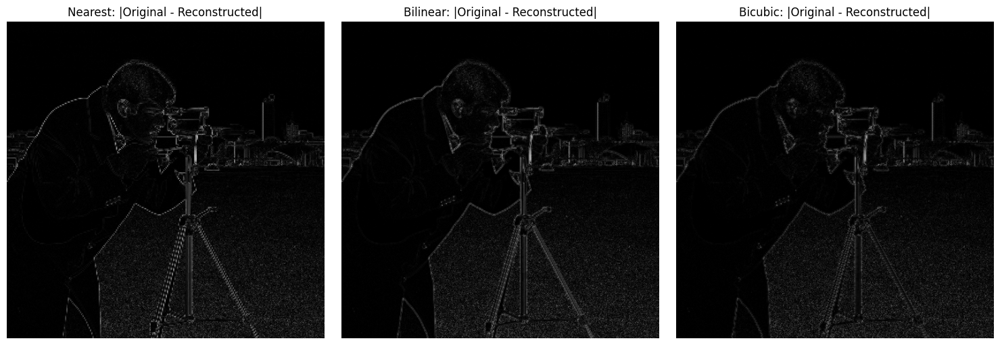

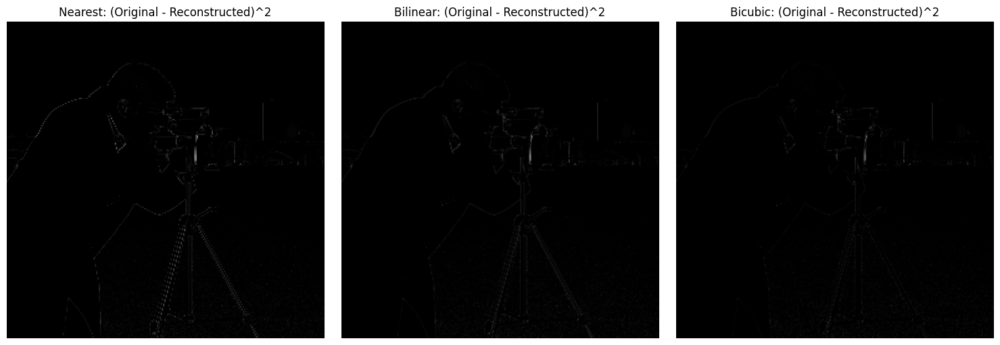


 ====================================================================== 128→512


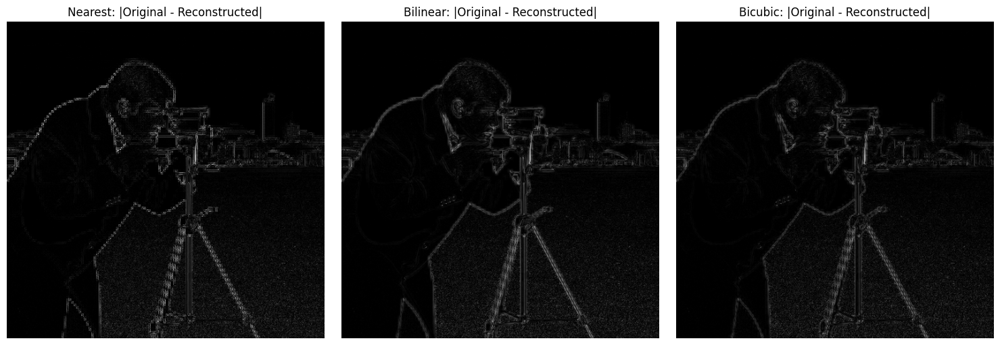

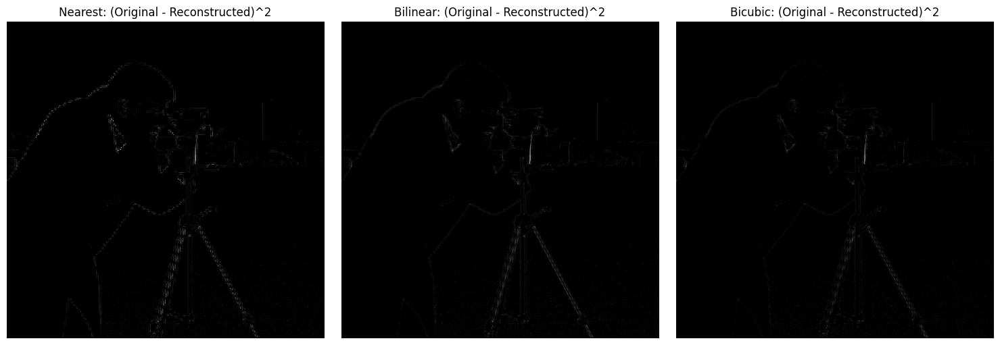

In [42]:
# Pixel-wise absolute-error and squared-error maps
for factor, recs in [("256→512", rec_256), ("128→512", rec_128)]:
    print("\n", "="*70, factor)
    abs_maps = [np.abs(original-recs[m]) for m in recs]
    sq_maps = [(original-recs[m])**2 for m in recs]

    show_images(abs_maps, [f"{m}: |Original - Reconstructed|" for m in recs],
                cols=3, figsize=(15,5), vmin=0, vmax=np.max(abs_maps))
    show_images(sq_maps, [f"{m}: (Original - Reconstructed)^2" for m in recs],
                cols=3, figsize=(15,5), vmin=0, vmax=np.max(sq_maps))


,Scale,Interpolation,Strong-edge preservation
0,256→512,Nearest,0.4985
1,256→512,Bilinear,0.4118
2,256→512,Bicubic,0.4798
3,128→512,Nearest,0.2982
4,128→512,Bilinear,0.1867
5,128→512,Bicubic,0.2828


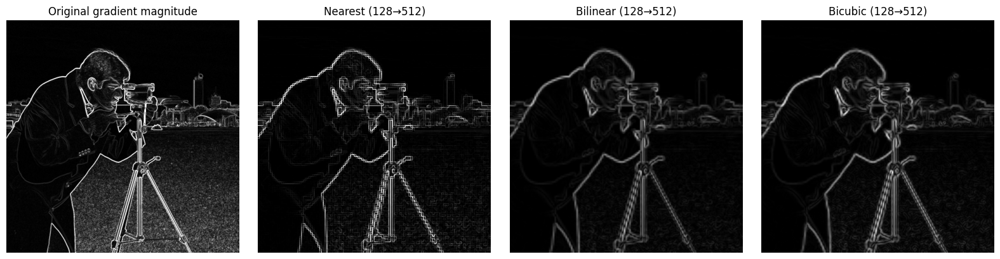

In [43]:
# Edge-preservation analysis using manually computed gradient magnitude
def manual_gradient(img):
    img = img.astype(np.float64)
    gx = np.zeros_like(img)
    gy = np.zeros_like(img)
    gx[:,1:-1] = (img[:,2:] - img[:,:-2]) / 2
    gy[1:-1,:] = (img[2:,:] - img[:-2,:]) / 2
    mag = np.sqrt(gx**2 + gy**2)
    return gx, gy, mag

_, _, grad_original = manual_gradient(original)

edge_rows = []
threshold = np.percentile(grad_original, 90)
edge_ref = grad_original > threshold

for factor, recs in [("256→512", rec_256), ("128→512", rec_128)]:
    for method, img in recs.items():
        _, _, gm = manual_gradient(img)
        edge = gm > threshold
        # Fraction of strong original edges still represented in reconstruction
        preservation = np.sum(edge_ref & edge) / (np.sum(edge_ref) + 1e-12)
        edge_rows.append([factor, method, preservation])

edge_metrics = pd.DataFrame(edge_rows, columns=["Scale", "Interpolation", "Strong-edge preservation"])
display(edge_metrics.round(4))

show_images([grad_original] + [manual_gradient(rec_128[m])[2] for m in rec_128],
            ["Original gradient magnitude"] + [f"{m} (128→512)" for m in rec_128],
            cols=4, figsize=(16,4), vmin=0, vmax=np.percentile(grad_original, 99))


### Q1 interpretation

**Expected trend:** bicubic generally gives the best visual smoothness and often the lowest reconstruction error because it uses a larger neighbourhood and a smoother interpolation model. Bilinear is usually a good compromise. Nearest-neighbour preserves hard pixel blocks and therefore produces visibly jagged/blocky edges.

The **128×128 → 512×512** reconstruction loses more information than **256×256 → 512×512** because the downsampling factor is larger. Interpolation can estimate missing values, but it cannot recreate details that were discarded during downsampling.

For the final report, use the numerical table generated above rather than hard-coding values; the exact values are produced by the notebook.

# Q2. Image Smoothing

The assignment asks for two grayscale images: one with fine detail and one with large smooth regions; salt-and-pepper noise is added to the first and Gaussian noise to the second. Box, weighted-average, Gaussian and median filters are then tested with at least three kernel sizes, evaluated visually and using MSE/PSNR, followed by a mixed-noise experiment and region-wise smoothing. 

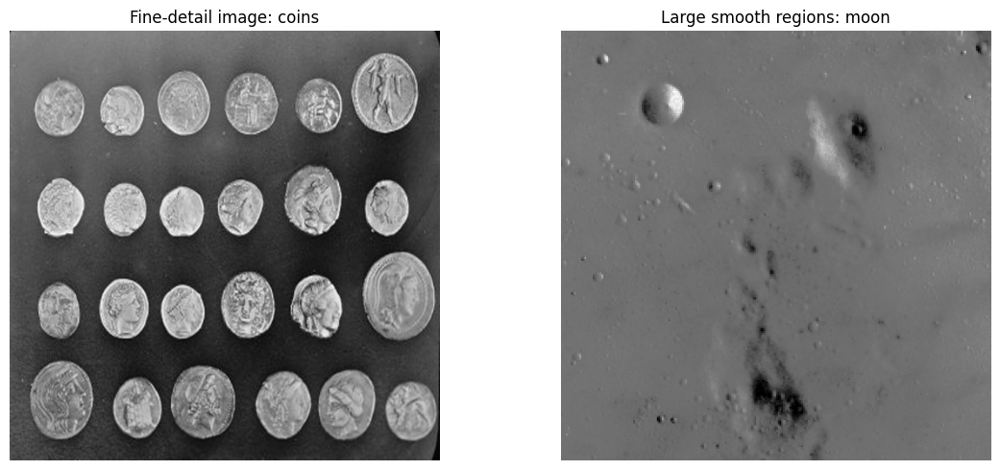

In [44]:
# Select source images
fine = img_as_float(data.coins())
smooth = img_as_float(data.moon())

# Put them on a common convenient size
fine = cv2.resize(fine, (512,512), interpolation=cv2.INTER_CUBIC)
smooth = cv2.resize(smooth, (512,512), interpolation=cv2.INTER_CUBIC)

show_images([fine, smooth], ["Fine-detail image: coins", "Large smooth regions: moon"],
            cols=2, figsize=(12,5))


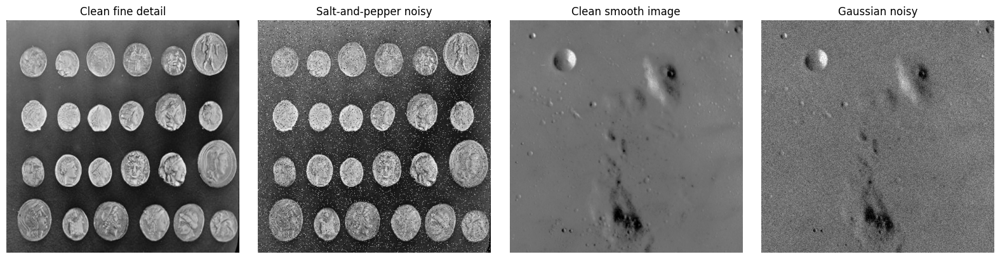

In [45]:
# Noise models
def add_salt_pepper(img, amount=0.06, salt_ratio=0.5):
    noisy = img.copy()
    n = int(amount * img.size)
    idx = np.random.choice(img.size, n, replace=False)
    flat = noisy.ravel()
    n_salt = int(n * salt_ratio)
    flat[idx[:n_salt]] = 1.0
    flat[idx[n_salt:]] = 0.0
    return noisy

def add_gaussian_noise(img, sigma=0.08):
    return np.clip(img + np.random.normal(0, sigma, img.shape), 0, 1)

sp_noisy = add_salt_pepper(fine, amount=0.06)
gauss_noisy = add_gaussian_noise(smooth, sigma=0.08)

show_images([fine, sp_noisy, smooth, gauss_noisy],
            ["Clean fine detail", "Salt-and-pepper noisy",
             "Clean smooth image", "Gaussian noisy"],
            cols=4, figsize=(16,4))


### Manual Box filter

The Box filter is implemented with an **integral image**, not with a built-in filtering function. This makes the implementation explicit and efficient enough for the assignment.

In [46]:
def box_filter_manual(img, k):
    assert k % 2 == 1, "Kernel size must be odd."
    pad = k // 2
    padded = np.pad(img, ((pad,pad),(pad,pad)), mode="reflect")

    # Integral image with one extra zero row/column
    integral = np.pad(padded, ((1,0),(1,0)), mode="constant")
    integral = integral.cumsum(axis=0).cumsum(axis=1)

    sums = (integral[k:, k:] - integral[:-k, k:]
            - integral[k:, :-k] + integral[:-k, :-k])
    return sums / (k*k)

def binomial_kernel(k):
    # Pascal-row weights -> a weighted-average kernel
    row = np.array([math.comb(k-1, i) for i in range(k)], dtype=np.float64)
    K = np.outer(row, row)
    return K / K.sum()

def weighted_filter(img, k):
    return ndimage.convolve(img, binomial_kernel(k), mode="reflect")

def gaussian_filter(img, k, sigma=None):
    if sigma is None:
        sigma = k / 6
    return ndimage.gaussian_filter(img, sigma=sigma, mode="reflect", radius=k//2)

def median_filter(img, k):
    return ndimage.median_filter(img, size=k, mode="reflect")

print("Example 5x5 weighted-average kernel:")
display(pd.DataFrame(binomial_kernel(5)).round(4))


Example 5x5 weighted-average kernel:


,0,1,2,3,4
0,0.0039,0.0156,0.0234,0.0156,0.0039
1,0.0156,0.0625,0.0938,0.0625,0.0156
2,0.0234,0.0938,0.1406,0.0938,0.0234
3,0.0156,0.0625,0.0938,0.0625,0.0156
4,0.0039,0.0156,0.0234,0.0156,0.0039


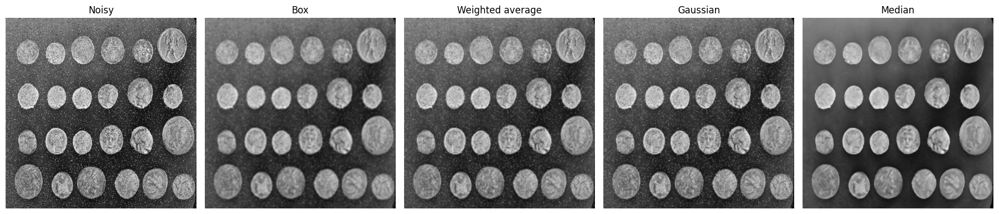

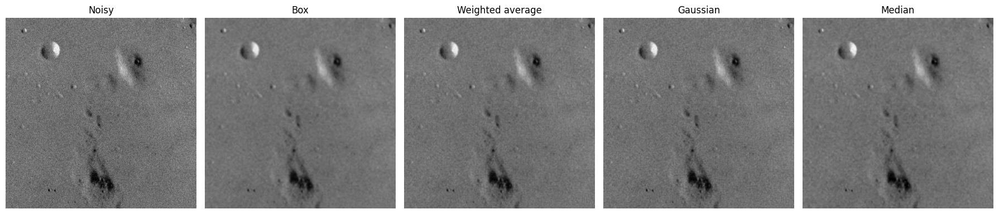

In [47]:
# Compare all four filters at k=5
filters_5_sp = {
    "Box": box_filter_manual(sp_noisy, 5),
    "Weighted average": weighted_filter(sp_noisy, 5),
    "Gaussian": gaussian_filter(sp_noisy, 5),
    "Median": median_filter(sp_noisy, 5)
}
filters_5_gauss = {
    "Box": box_filter_manual(gauss_noisy, 5),
    "Weighted average": weighted_filter(gauss_noisy, 5),
    "Gaussian": gaussian_filter(gauss_noisy, 5),
    "Median": median_filter(gauss_noisy, 5)
}

show_images([sp_noisy] + list(filters_5_sp.values()),
            ["Noisy"] + list(filters_5_sp.keys()),
            cols=5, figsize=(18,4))
show_images([gauss_noisy] + list(filters_5_gauss.values()),
            ["Noisy"] + list(filters_5_gauss.keys()),
            cols=5, figsize=(18,4))


In [48]:
# Test three kernel sizes
kernel_sizes = [3, 5, 9]
all_q2_rows = []

for noise_name, noisy, clean in [
    ("Salt & Pepper", sp_noisy, fine),
    ("Gaussian", gauss_noisy, smooth)
]:
    for k in kernel_sizes:
        outputs = {
            "Box": box_filter_manual(noisy, k),
            "Weighted average": weighted_filter(noisy, k),
            "Gaussian": gaussian_filter(noisy, k),
            "Median": median_filter(noisy, k)
        }
        for method, out in outputs.items():
            all_q2_rows.append({
                "Noise": noise_name, "Kernel": k, "Filter": method,
                "MSE": mse(clean, out), "PSNR (dB)": psnr(clean, out)
            })

q2_metrics = pd.DataFrame(all_q2_rows)
display(q2_metrics.sort_values(["Noise","PSNR (dB)"], ascending=[True,False]).round(5))


,Noise,Kernel,Filter,MSE,PSNR (dB)
20,Gaussian,9,Box,0.00034,34.66509
22,Gaussian,9,Gaussian,0.00036,34.48978
21,Gaussian,9,Weighted average,0.00037,34.32750
23,Gaussian,9,Median,0.00038,34.21556
16,Gaussian,5,Box,0.00040,34.01492
19,Gaussian,5,Median,0.00053,32.71923
17,Gaussian,5,Weighted average,0.00056,32.48384
12,Gaussian,3,Box,0.00080,30.94995
18,Gaussian,5,Gaussian,0.00080,30.94289
13,Gaussian,3,Weighted average,0.00096,30.17575


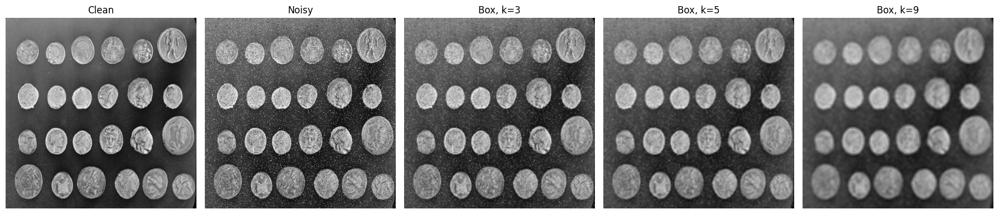

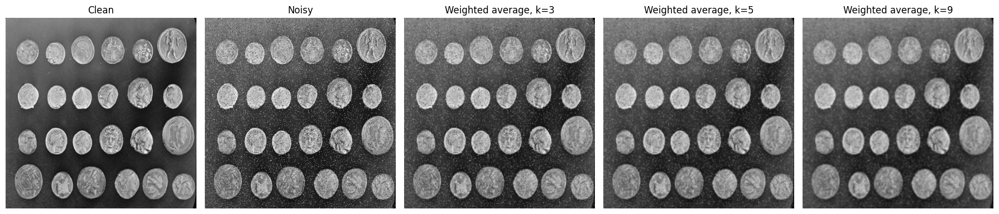

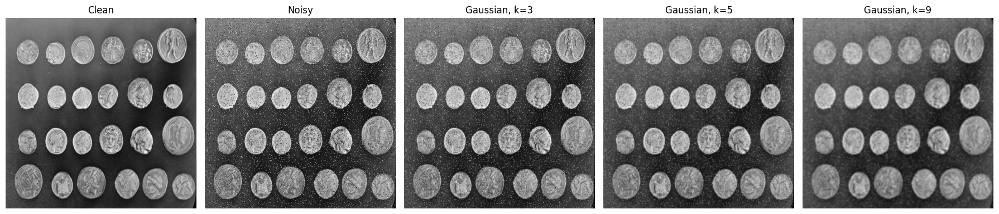

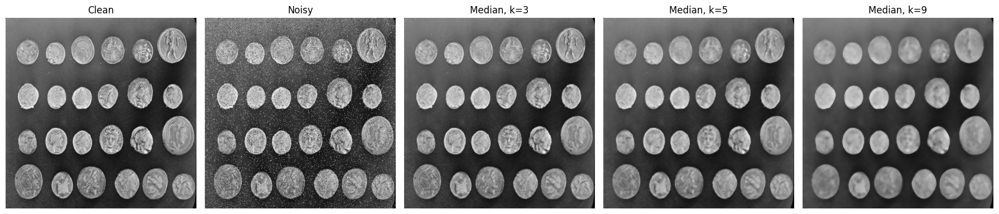

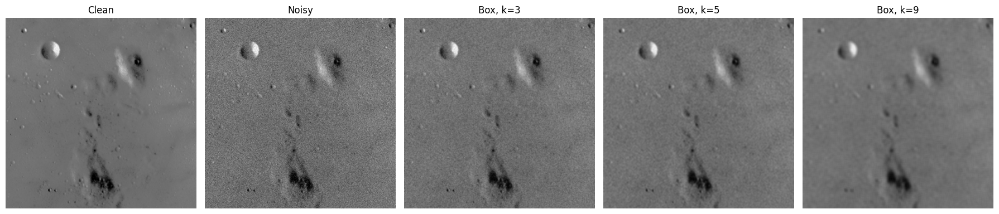

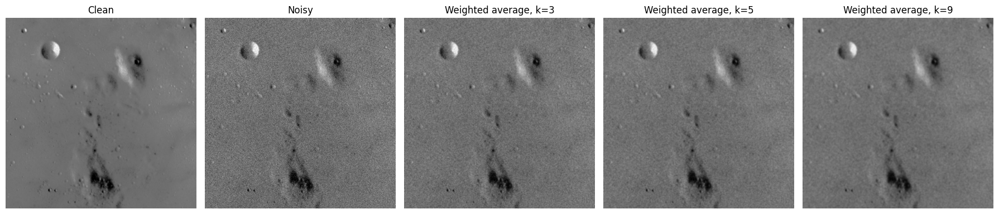

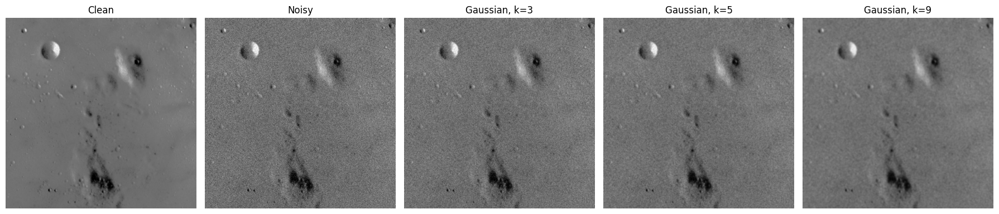

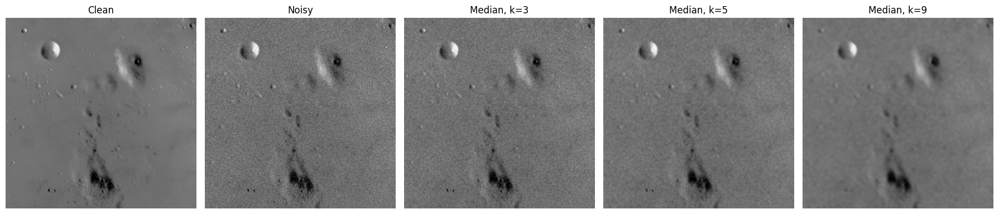

In [49]:
# Visual effect of increasing kernel size
for noise_name, noisy, clean in [
    ("Salt & Pepper", sp_noisy, fine),
    ("Gaussian", gauss_noisy, smooth)
]:
    for method in ["Box", "Weighted average", "Gaussian", "Median"]:
        outs = []
        for k in kernel_sizes:
            if method == "Box": out = box_filter_manual(noisy, k)
            elif method == "Weighted average": out = weighted_filter(noisy, k)
            elif method == "Gaussian": out = gaussian_filter(noisy, k)
            else: out = median_filter(noisy, k)
            outs.append(out)
        show_images([clean, noisy] + outs,
                    ["Clean", "Noisy"] + [f"{method}, k={k}" for k in kernel_sizes],
                    cols=5, figsize=(18,4))


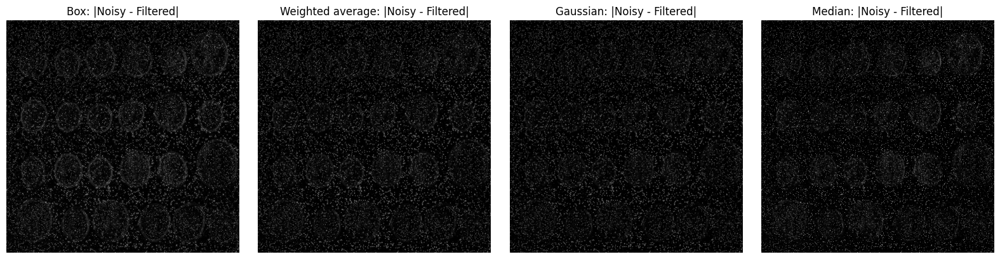

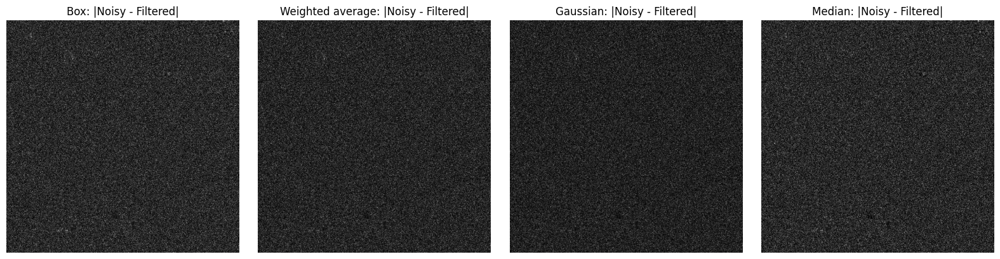

In [50]:
# Absolute-difference maps: D(x,y)=|I(x,y)-If(x,y)|
# Here I is the noisy image and If is the filtered image, exactly as stated in the assignment.
for noise_name, noisy, clean in [
    ("Salt & Pepper", sp_noisy, fine),
    ("Gaussian", gauss_noisy, smooth)
]:
    outputs = {
        "Box": box_filter_manual(noisy, 5),
        "Weighted average": weighted_filter(noisy, 5),
        "Gaussian": gaussian_filter(noisy, 5),
        "Median": median_filter(noisy, 5)
    }
    diffs = [np.abs(noisy-out) for out in outputs.values()]
    show_images(diffs, [f"{m}: |Noisy - Filtered|" for m in outputs],
                cols=4, figsize=(16,4), vmin=0, vmax=np.max(diffs))


In [51]:
# Automatically identify the best filter for each noise type using PSNR
best_by_noise = (q2_metrics.sort_values("PSNR (dB)", ascending=False)
                 .groupby("Noise", as_index=False).first())

print("Best single configuration for each noise type:")
display(best_by_noise[["Noise","Filter","Kernel","MSE","PSNR (dB)"]].round(5))


Best single configuration for each noise type:


,Noise,Filter,Kernel,MSE,PSNR (dB)
0,Gaussian,Box,9,0.00034,34.66509
1,Salt & Pepper,Median,3,0.00049,33.08057


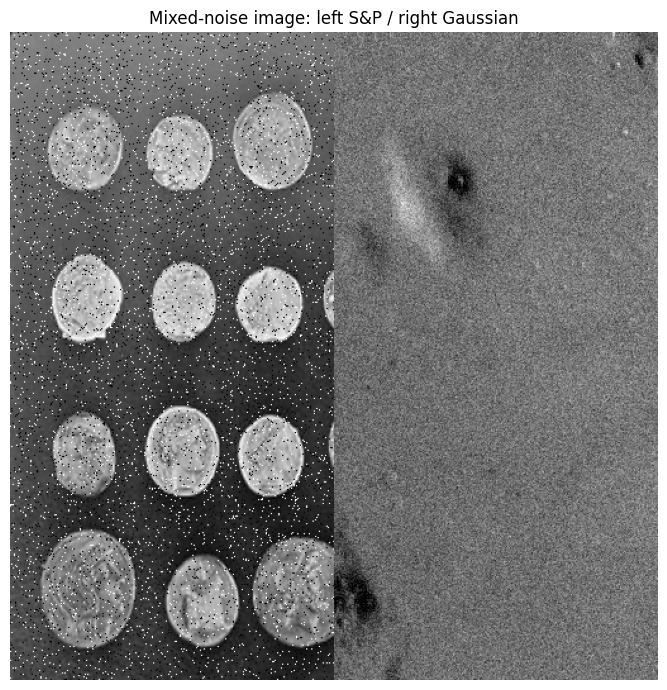

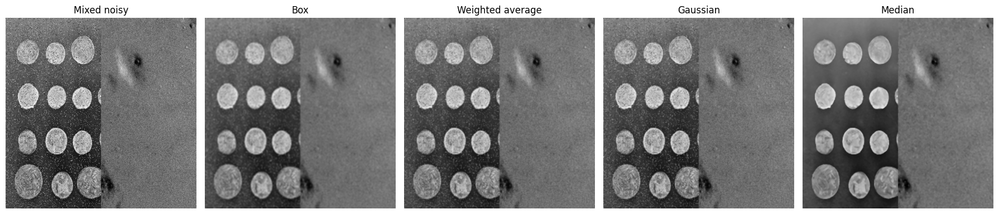

In [52]:
# Mixed-noise image: left = salt-and-pepper, right = Gaussian
mixed = np.empty_like(fine)
mid = mixed.shape[1] // 2
mixed[:, :mid] = sp_noisy[:, :mid]
mixed[:, mid:] = gauss_noisy[:, mid:]

show_images([mixed], ["Mixed-noise image: left S&P / right Gaussian"],
            cols=1, figsize=(7,7))

# Apply every filter over the complete mixed image
mixed_outputs = {}
for method in ["Box","Weighted average","Gaussian","Median"]:
    if method == "Box": mixed_outputs[method] = box_filter_manual(mixed, 5)
    elif method == "Weighted average": mixed_outputs[method] = weighted_filter(mixed, 5)
    elif method == "Gaussian": mixed_outputs[method] = gaussian_filter(mixed, 5)
    else: mixed_outputs[method] = median_filter(mixed, 5)

show_images([mixed] + list(mixed_outputs.values()),
            ["Mixed noisy"] + list(mixed_outputs.keys()),
            cols=5, figsize=(18,4))


In [53]:
# Evaluate mixed-image filters against the corresponding clean halves
# Left half is compared with 'fine'; right half with 'smooth'.
mixed_rows = []
for method, out in mixed_outputs.items():
    left_mse = mse(fine[:, :mid], out[:, :mid])
    right_mse = mse(smooth[:, mid:], out[:, mid:])
    left_psnr = psnr(fine[:, :mid], out[:, :mid])
    right_psnr = psnr(smooth[:, mid:], out[:, mid:])
    mixed_rows.append([method, left_mse, left_psnr, right_mse, right_psnr,
                       (left_mse + right_mse)/2])

mixed_metrics = pd.DataFrame(
    mixed_rows,
    columns=["Filter","Left MSE","Left PSNR","Right MSE","Right PSNR","Mean MSE"]
)
display(mixed_metrics.sort_values("Mean MSE").round(5))


,Filter,Left MSE,Left PSNR,Right MSE,Right PSNR,Mean MSE
3,Median,0.00106,29.73231,0.00054,32.67435,0.00080
1,Weighted average,0.00238,26.23456,0.00057,32.44325,0.00147
0,Box,0.00280,25.52804,0.00042,33.79360,0.00161
2,Gaussian,0.00279,25.53846,0.00080,30.94545,0.00180


Left half (S&P): Median, k=3
Right half (Gaussian): Box, k=9


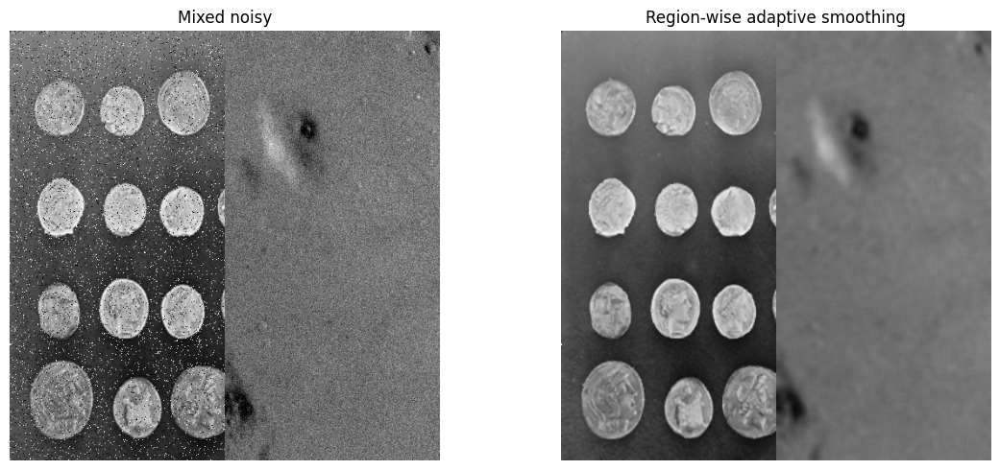

In [54]:
# Region-wise smoothing:
# choose the best filter for the S&P half and the best filter for the Gaussian half
best_sp_filter = best_by_noise.loc[best_by_noise["Noise"]=="Salt & Pepper", "Filter"].iloc[0]
best_sp_k = int(best_by_noise.loc[best_by_noise["Noise"]=="Salt & Pepper", "Kernel"].iloc[0])
best_g_filter = best_by_noise.loc[best_by_noise["Noise"]=="Gaussian", "Filter"].iloc[0]
best_g_k = int(best_by_noise.loc[best_by_noise["Noise"]=="Gaussian", "Kernel"].iloc[0])

def apply_filter(img, method, k):
    if method == "Box": return box_filter_manual(img, k)
    if method == "Weighted average": return weighted_filter(img, k)
    if method == "Gaussian": return gaussian_filter(img, k)
    if method == "Median": return median_filter(img, k)
    raise ValueError(method)

regionwise = np.empty_like(mixed)
regionwise[:, :mid] = apply_filter(mixed[:, :mid], best_sp_filter, best_sp_k)
regionwise[:, mid:] = apply_filter(mixed[:, mid:], best_g_filter, best_g_k)

print(f"Left half (S&P): {best_sp_filter}, k={best_sp_k}")
print(f"Right half (Gaussian): {best_g_filter}, k={best_g_k}")

show_images([mixed, regionwise],
            ["Mixed noisy", "Region-wise adaptive smoothing"],
            cols=2, figsize=(12,5))


### Q2 interpretation

- **Salt-and-pepper noise:** median filtering is usually strongest because the order-statistic operation rejects isolated black/white impulses while retaining edges better than averaging.
- **Gaussian noise:** Gaussian or weighted averaging generally performs well because the noise is distributed over many pixels and averaging reduces its variance.
- Increasing the kernel size usually removes more noise but also increases **blur/detail loss**.
- A single filter need not be optimal over the mixed image. Region-wise selection is therefore a simple adaptive strategy.

The notebook uses the measured MSE/PSNR table to make the final selection rather than assuming the result.

# Q3. Hybrid Images

The assignment defines a hybrid image as

\[
H = \alpha LPF(I_1)+\beta HPF(I_2), \qquad HPF(I_2)=I_2-LPF(I_2)
\]

and asks for at least two aligned pairs, spatial- and frequency-domain implementations, parameter experiments, Gaussian/Laplacian pyramids, and a bilateral-filter pyramid variant. fileciteturn0file0L43-L72

For a reproducible Colab notebook without external image uploads, we use two built-in image pairs. Each second image is geometrically transformed first, then aligned back using ECC registration. This demonstrates the required geometric-alignment step.

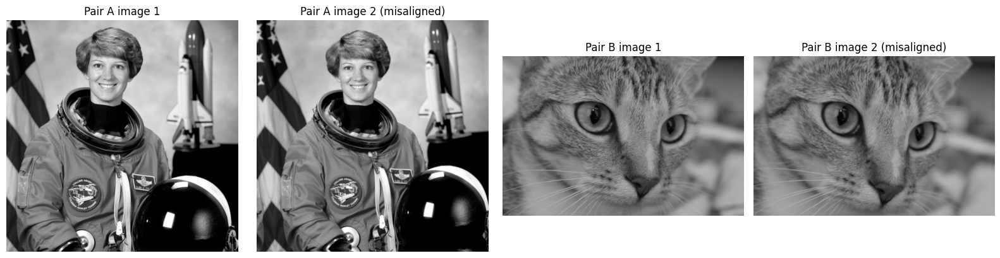

In [55]:
# Build two reproducible image pairs from standard skimage images.
# Pair A: astronaut face + geometrically transformed astronaut
# Pair B: camera + geometrically transformed coins
pairA_1 = color.rgb2gray(data.astronaut())
pairA_2 = color.rgb2gray(data.astronaut())

pairB_1 = color.rgb2gray(data.chelsea())
pairB_2 = color.rgb2gray(data.chelsea())

def make_transform(img, angle=0, scale=1.0, tx=0, ty=0):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w/2,h/2), angle, scale)
    M[:,2] += [tx,ty]
    return cv2.warpAffine(img, M, (w,h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

pairA_2_misaligned = make_transform(pairA_2, angle=5, scale=0.96, tx=10, ty=-6)
pairB_2_misaligned = make_transform(pairB_2, angle=-4, scale=1.03, tx=-8, ty=7)

show_images([pairA_1, pairA_2_misaligned, pairB_1, pairB_2_misaligned],
            ["Pair A image 1", "Pair A image 2 (misaligned)",
             "Pair B image 1", "Pair B image 2 (misaligned)"],
            cols=4, figsize=(16,4))


Pair A ECC correlation: 0.9978057072808109
Pair B ECC correlation: 0.992637215430895


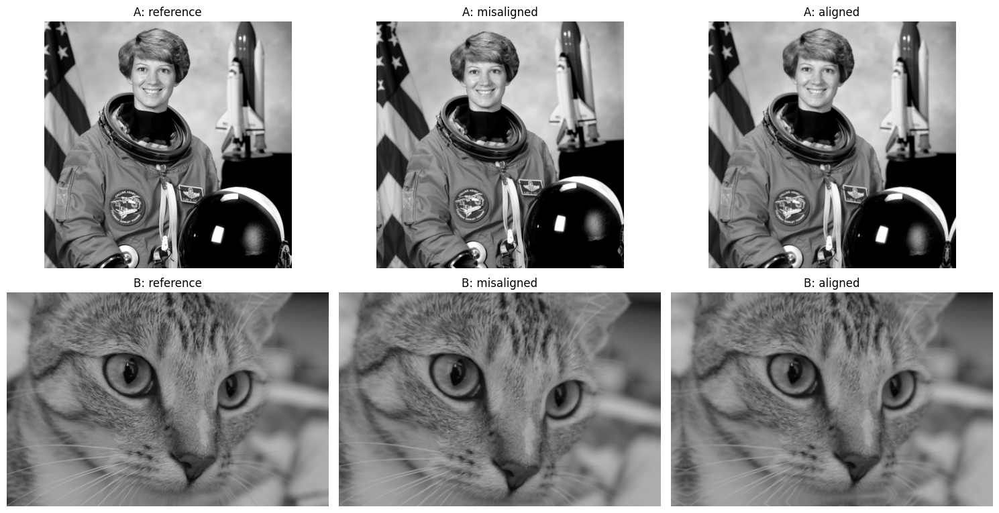

In [56]:
# ECC alignment: estimate an affine transform from image 2 to image 1
def align_ecc(reference, moving):
    ref = cv2.normalize(reference.astype(np.float32), None, 0, 1, cv2.NORM_MINMAX)
    mov = cv2.normalize(moving.astype(np.float32), None, 0, 1, cv2.NORM_MINMAX)
    warp = np.eye(2,3, dtype=np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 300, 1e-6)
    cc, warp = cv2.findTransformECC(ref, mov, warp, cv2.MOTION_AFFINE, criteria, None, 1)
    aligned = cv2.warpAffine(moving, warp, (reference.shape[1], reference.shape[0]),
                              flags=cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP,
                              borderMode=cv2.BORDER_REFLECT)
    return aligned, warp, cc

A2_aligned, A_warp, A_cc = align_ecc(pairA_1, pairA_2_misaligned)
B2_aligned, B_warp, B_cc = align_ecc(pairB_1, pairB_2_misaligned)

print("Pair A ECC correlation:", A_cc)
print("Pair B ECC correlation:", B_cc)

show_images([pairA_1, pairA_2_misaligned, A2_aligned,
             pairB_1, pairB_2_misaligned, B2_aligned],
            ["A: reference","A: misaligned","A: aligned",
             "B: reference","B: misaligned","B: aligned"],
            cols=3, figsize=(15,8))


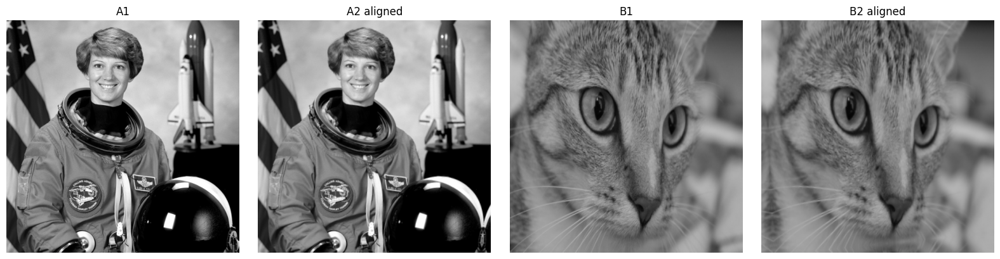

In [57]:
# Put images in a common 512x512 canvas for easy hybrid construction
def resize512(img):
    return cv2.resize(img, (512,512), interpolation=cv2.INTER_AREA)

A1, A2 = resize512(pairA_1), resize512(A2_aligned)
B1, B2 = resize512(pairB_1), resize512(B2_aligned)

show_images([A1,A2,B1,B2], ["A1","A2 aligned","B1","B2 aligned"],
            cols=4, figsize=(16,4))


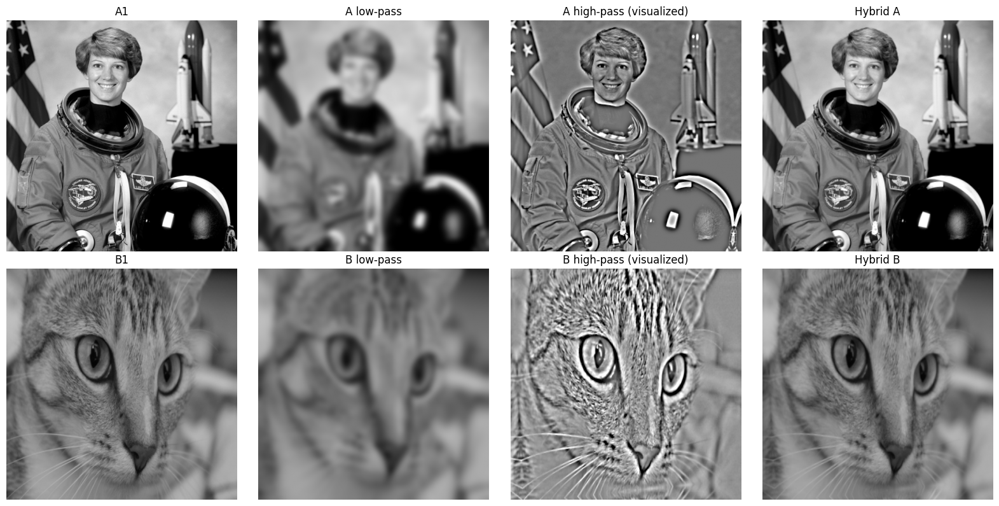

In [58]:
# Spatial-domain hybrid image
def spatial_hybrid(I1, I2, sigma=5, alpha=1.0, beta=1.0):
    low = cv2.GaussianBlur(I1, (0,0), sigmaX=sigma, sigmaY=sigma)
    low2 = cv2.GaussianBlur(I2, (0,0), sigmaX=sigma, sigmaY=sigma)
    high = I2 - low2       # KEEP signed values for construction
    H = alpha*low + beta*high
    return np.clip(H, 0, 1), low, high

HA, A_low, A_high = spatial_hybrid(A1, A2, sigma=6, alpha=1.0, beta=1.0)
HB, B_low, B_high = spatial_hybrid(B1, B2, sigma=6, alpha=1.0, beta=1.0)

show_images([A1,A_low,normalize_for_display(A_high),HA,
             B1,B_low,normalize_for_display(B_high),HB],
            ["A1","A low-pass","A high-pass (visualized)","Hybrid A",
             "B1","B low-pass","B high-pass (visualized)","Hybrid B"],
            cols=4, figsize=(16,8))


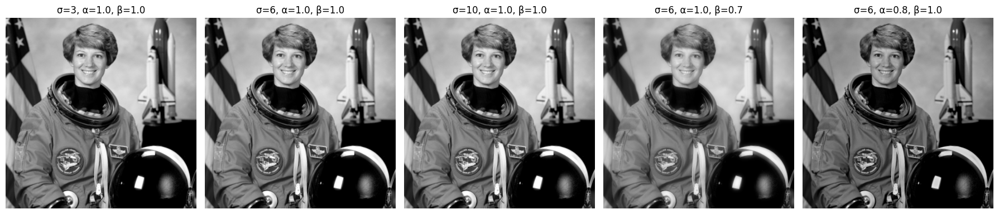

In [59]:
# Parameter experiment: sigma and component weights
experiments = [
    (3, 1.0, 1.0),
    (6, 1.0, 1.0),
    (10, 1.0, 1.0),
    (6, 1.0, 0.7),
    (6, 0.8, 1.0),
]
outs = []
titles = []
for sigma, alpha, beta in experiments:
    h, _, _ = spatial_hybrid(A1, A2, sigma, alpha, beta)
    outs.append(h)
    titles.append(f"σ={sigma}, α={alpha}, β={beta}")

show_images(outs, titles, cols=5, figsize=(18,4))


Spatial time:   12.92 ms
Frequency time: 40.69 ms


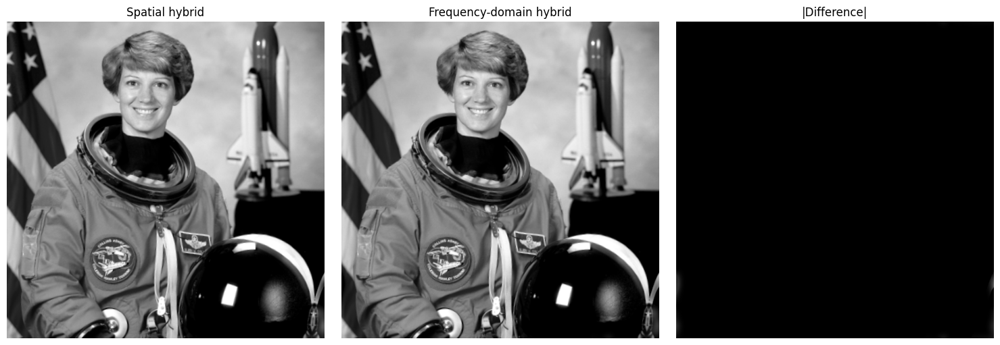

In [60]:
# Frequency-domain Gaussian low/high-pass filtering
def frequency_hybrid(I1, I2, sigma=6, alpha=1.0, beta=1.0):
    h, w = I1.shape
    yy, xx = np.mgrid[0:h, 0:w]
    cy, cx = h/2, w/2

    # A spatial Gaussian with standard deviation sigma has a
    # Gaussian-shaped frequency response whose width is approximately
    # N/(2*pi*sigma). Use the image size to match the spatial parameter.
    D2 = (xx-cx)**2 + (yy-cy)**2
    sigma_f = min(h,w) / (2*np.pi*sigma)
    low_mask = np.exp(-D2/(2*sigma_f**2))
    high_mask = 1 - low_mask

    F1 = np.fft.fftshift(np.fft.fft2(I1))
    F2 = np.fft.fftshift(np.fft.fft2(I2))

    low1 = np.real(np.fft.ifft2(np.fft.ifftshift(F1*low_mask)))
    high2 = np.real(np.fft.ifft2(np.fft.ifftshift(F2*high_mask)))
    H = np.clip(alpha*low1 + beta*high2, 0, 1)
    return H, low1, high2, low_mask

t0 = time.perf_counter()
HA_freq, _, _, _ = frequency_hybrid(A1,A2,sigma=6)
freq_time = time.perf_counter()-t0

t0 = time.perf_counter()
HA_spatial, _, _ = spatial_hybrid(A1,A2,sigma=6)
spatial_time = time.perf_counter()-t0

print(f"Spatial time:   {spatial_time*1000:.2f} ms")
print(f"Frequency time: {freq_time*1000:.2f} ms")

show_images([HA_spatial, HA_freq, np.abs(HA_spatial-HA_freq)],
            ["Spatial hybrid", "Frequency-domain hybrid", "|Difference|"],
            cols=3, figsize=(15,5))


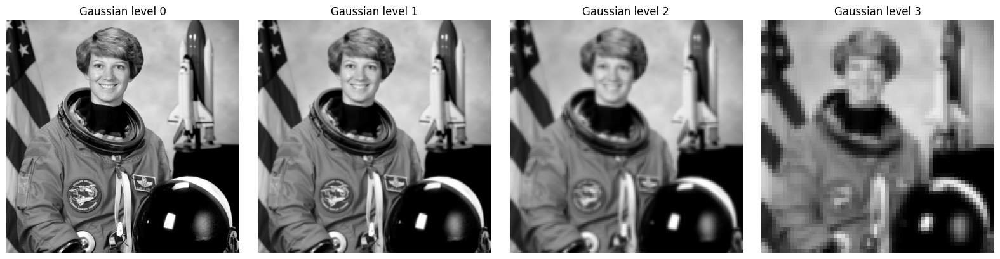

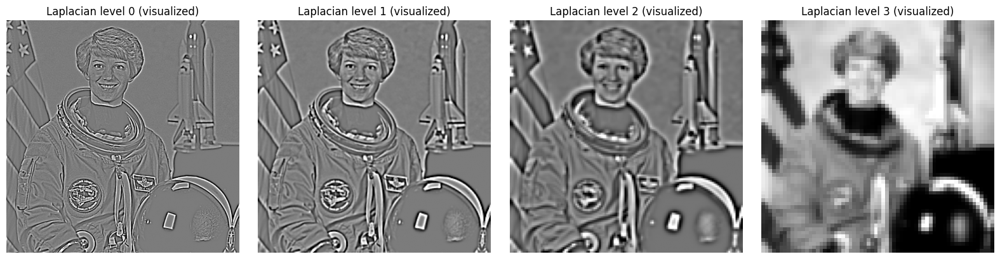

In [61]:
# Gaussian pyramid
def gaussian_pyramid(img, levels=4):
    pyr = [img]
    for _ in range(levels-1):
        pyr.append(cv2.pyrDown(pyr[-1]))
    return pyr

def laplacian_pyramid(img, levels=4):
    G = gaussian_pyramid(img, levels)
    L = []
    for i in range(levels-1):
        up = cv2.pyrUp(G[i+1], dstsize=(G[i].shape[1], G[i].shape[0]))
        L.append(G[i] - up)
    L.append(G[-1])
    return G, L

G1 = gaussian_pyramid(A1, 4)
G2 = gaussian_pyramid(A2, 4)
_, L1 = laplacian_pyramid(A1, 4)
_, L2 = laplacian_pyramid(A2, 4)

show_images(G1, [f"Gaussian level {i}" for i in range(4)],
            cols=4, figsize=(16,4))
show_images([normalize_for_display(x) for x in L2],
            [f"Laplacian level {i} (visualized)" for i in range(4)],
            cols=4, figsize=(16,4))


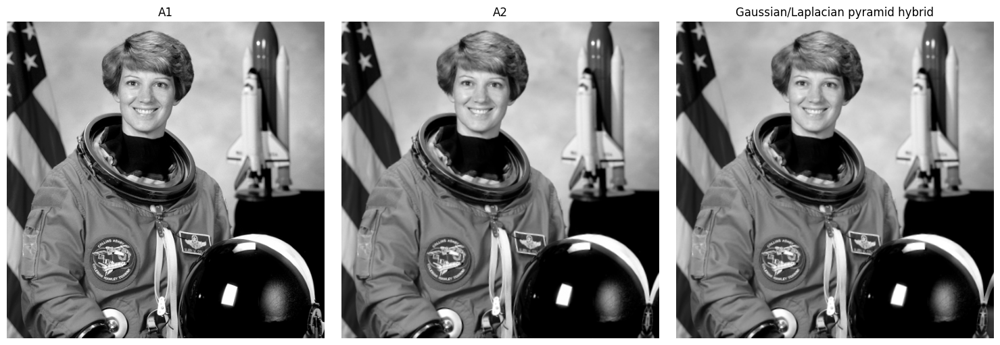

In [62]:
# Pyramid hybrid: low-frequency information from A1 + high-frequency information from A2
# Use low-frequency Gaussian pyramid levels from A1 and detail levels from A2.
mixed_L = []
for i in range(3):
    mixed_L.append(L2[i])
mixed_L.append(G1[-1])

def reconstruct_laplacian(L):
    current = L[-1]
    for i in range(len(L)-2, -1, -1):
        current = cv2.pyrUp(current, dstsize=(L[i].shape[1], L[i].shape[0])) + L[i]
    return current

H_pyr = np.clip(reconstruct_laplacian(mixed_L), 0, 1)

show_images([A1,A2,H_pyr], ["A1","A2","Gaussian/Laplacian pyramid hybrid"],
            cols=3, figsize=(15,5))


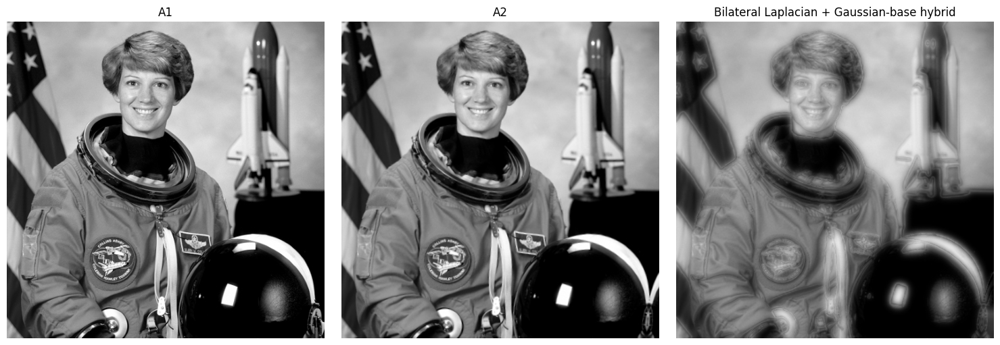

In [63]:
# Bilateral-filter Laplacian pyramid
def bilateral_lowpass(img, d=9, sigma_color=0.08, sigma_space=5):
    # OpenCV expects 8-bit values for convenient bilateral filtering.
    u8 = np.clip(img*255,0,255).astype(np.uint8)
    out = cv2.bilateralFilter(u8, d=d, sigmaColor=sigma_color*255, sigmaSpace=sigma_space)
    return out.astype(np.float32)/255.0

def bilateral_laplacian_pyramid(img, levels=4):
    G = [img]
    for _ in range(levels-1):
        low = bilateral_lowpass(G[-1])
        G.append(cv2.pyrDown(low))

    L = []
    for i in range(levels-1):
        # Bilateral low-pass at current level defines the smooth component.
        low = bilateral_lowpass(G[i])
        L.append(G[i] - low)
    L.append(G[-1])
    return G, L

BG1, BL1 = bilateral_laplacian_pyramid(A1, 4)
BG2, BL2 = bilateral_laplacian_pyramid(A2, 4)

BL_mix = BL2[:-1] + [BG1[-1]]
H_bilateral_pyr = np.clip(reconstruct_laplacian(BL_mix), 0, 1)

show_images([A1,A2,H_bilateral_pyr],
            ["A1","A2","Bilateral Laplacian + Gaussian-base hybrid"],
            cols=3, figsize=(15,5))


### Q3 interpretation

- **Alignment matters:** if corresponding features are shifted, the low-frequency structure and high-frequency details do not overlap correctly, producing ghosting/double edges.
- **Frequency separation matters:** the low-pass component should contain broad shapes, while the high-pass component should mainly contain fine transitions/details.
- **Sigma:** small sigma keeps more high-frequency content in the low-pass image; large sigma produces stronger separation.
- **Weights:** increasing β strengthens the detailed/high-frequency image; increasing α strengthens the low-frequency image.
- The assignment specifically warns that high-pass values can be negative; therefore they are normalized only for display, while the signed values are used in hybrid construction. 

# Q4. Edge Detection and Analysis

The assignment asks for x/y first derivatives, gradient magnitude/direction, thresholded binary edge maps, a second-order derivative, LoG and Canny, followed by comparisons of localization, continuity, thickness and fine-detail detection. It also requires the first- and second-order derivative operations to be implemented without directly using built-in edge detectors. 
We use:
1. `camera` — clearly defined object/structure boundaries.
2. `coins` — many fine boundaries and details.

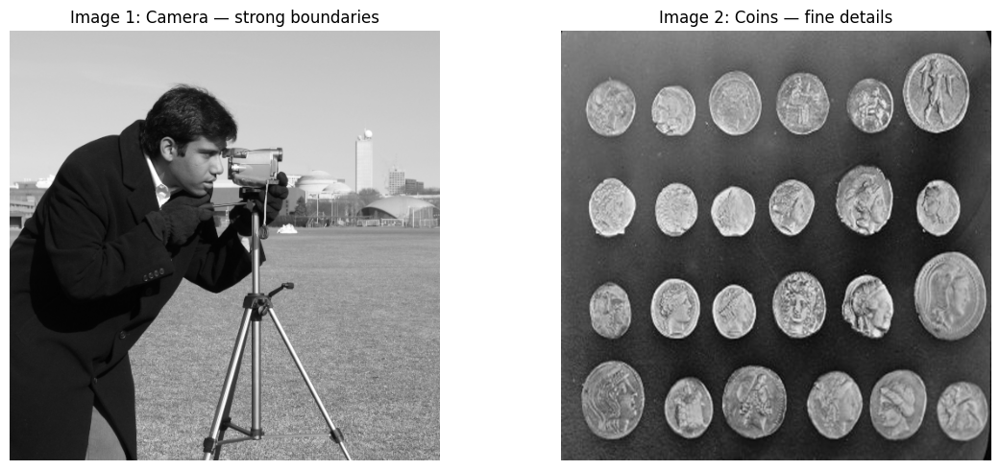

In [64]:
# Q4 images
edge_img1 = img_as_float(data.camera())
edge_img2 = cv2.resize(img_as_float(data.coins()), (512,512), interpolation=cv2.INTER_CUBIC)

show_images([edge_img1, edge_img2],
            ["Image 1: Camera — strong boundaries",
             "Image 2: Coins — fine details"],
            cols=2, figsize=(12,5))


### Manual first-order derivatives

We use central differences:

\[
G_x(x,y) \approx \frac{I(x+1,y)-I(x-1,y)}{2},\qquad
G_y(x,y) \approx \frac{I(x,y+1)-I(x,y-1)}{2}.
\]

The gradient magnitude and direction are

\[
|G|=\sqrt{G_x^2+G_y^2},\qquad
\theta=\tan^{-1}(G_y/G_x).
\]

No built-in edge detector is used.

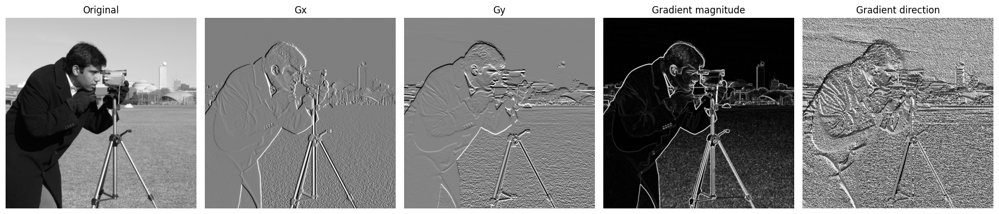

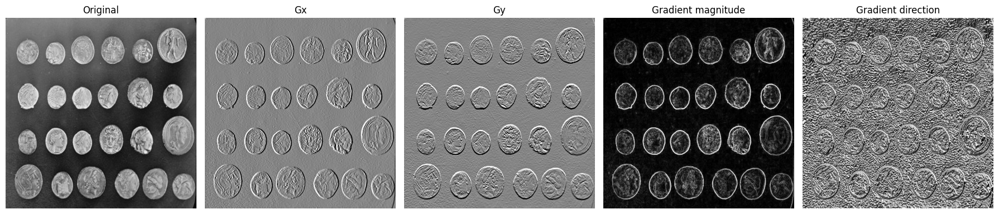

In [65]:
def first_derivatives_manual(img):
    img = img.astype(np.float64)
    gx = np.zeros_like(img)
    gy = np.zeros_like(img)
    gx[:,1:-1] = (img[:,2:] - img[:,:-2]) / 2.0
    gy[1:-1,:] = (img[2:,:] - img[:-2,:]) / 2.0
    magnitude = np.sqrt(gx**2 + gy**2)
    direction = np.arctan2(gy, gx)
    return gx, gy, magnitude, direction

gx1, gy1, mag1, dir1 = first_derivatives_manual(edge_img1)
gx2, gy2, mag2, dir2 = first_derivatives_manual(edge_img2)

show_images([edge_img1, normalize_for_display(gx1), normalize_for_display(gy1),
             normalize_for_display(mag1), (dir1+np.pi)/(2*np.pi)],
            ["Original","Gx","Gy","Gradient magnitude","Gradient direction"],
            cols=5, figsize=(18,4))

show_images([edge_img2, normalize_for_display(gx2), normalize_for_display(gy2),
             normalize_for_display(mag2), (dir2+np.pi)/(2*np.pi)],
            ["Original","Gx","Gy","Gradient magnitude","Gradient direction"],
            cols=5, figsize=(18,4))


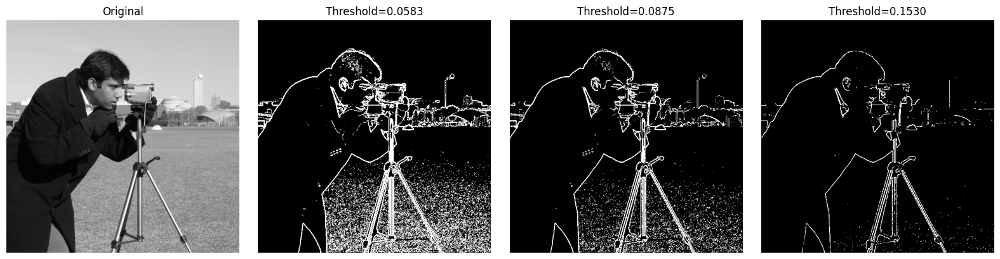

Camera thresholds: [np.float64(0.05829830881301377), np.float64(0.08753535013941068), np.float64(0.15295374508436388)]


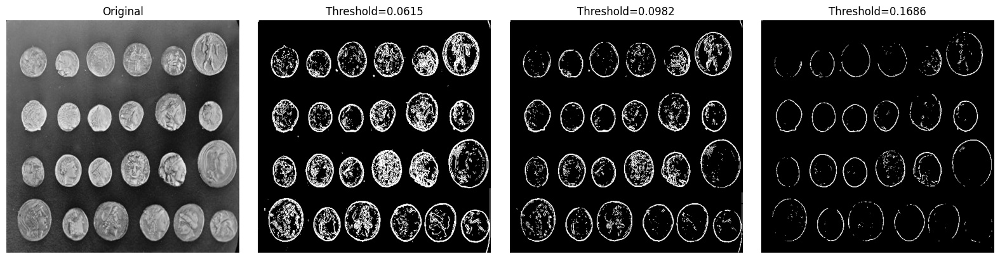

Coins thresholds: [np.float64(0.06150106061380374), np.float64(0.09818303636553474), np.float64(0.16861970262528733)]


In [66]:
# Three gradient thresholds
def threshold_edges(magnitude, threshold):
    return (magnitude >= threshold).astype(np.float32)

for name, img, mag in [("Camera", edge_img1, mag1), ("Coins", edge_img2, mag2)]:
    thresholds = [np.percentile(mag, p) for p in [85, 92, 97]]
    edges = [threshold_edges(mag,t) for t in thresholds]
    show_images([img]+edges,
                ["Original"]+[f"Threshold={t:.4f}" for t in thresholds],
                cols=4, figsize=(16,4))
    print(name, "thresholds:", thresholds)


**Threshold interpretation:** a low threshold detects weak/fine edges but also admits more noise and unwanted responses. A high threshold suppresses weak responses, which can cause genuine but low-contrast edges to disappear.

### Manual second-order derivative (Laplacian)

# We use the 4-neighbour discrete Laplacian:

\[
\nabla^2 I =
I(x+1,y)+I(x-1,y)+I(x,y+1)+I(x,y-1)-4I(x,y).
\]

# This is implemented directly with array shifts.

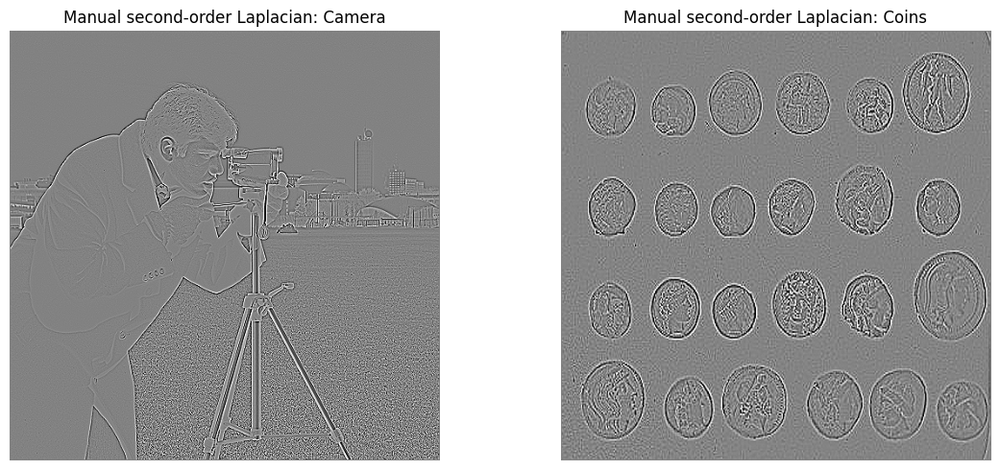

In [67]:
def laplacian_manual(img):
    img = img.astype(np.float64)
    out = np.zeros_like(img)
    out[1:-1,1:-1] = (
        img[:-2,1:-1] + img[2:,1:-1] +
        img[1:-1,:-2] + img[1:-1,2:] -
        4*img[1:-1,1:-1]
    )
    return out

lap1 = laplacian_manual(edge_img1)
lap2 = laplacian_manual(edge_img2)

show_images([normalize_for_display(lap1), normalize_for_display(lap2)],
            ["Manual second-order Laplacian: Camera",
             "Manual second-order Laplacian: Coins"],
            cols=2, figsize=(12,5))


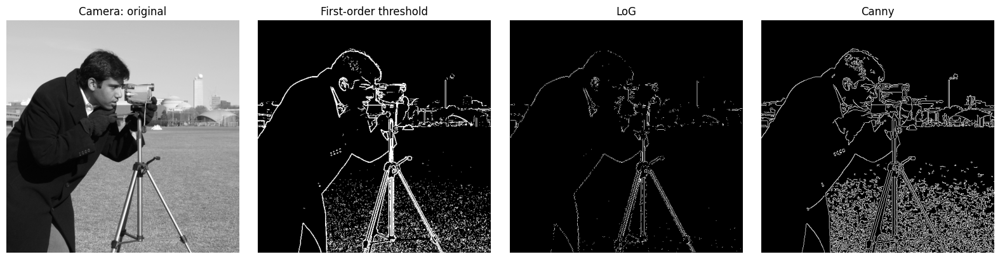

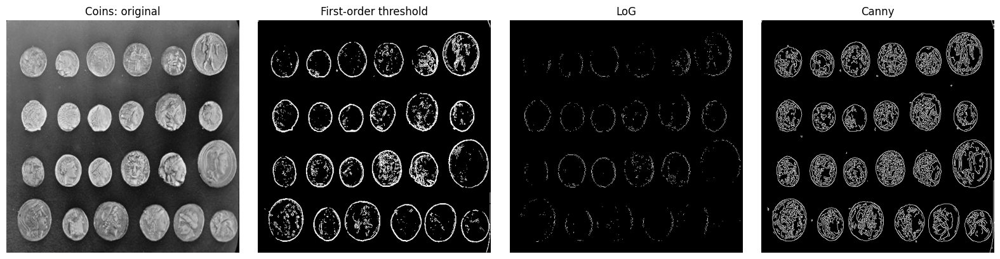

In [68]:
# LoG and Canny
def log_edges(img, sigma=1.4, threshold_percentile=92):
    sm = ndimage.gaussian_filter(img, sigma=sigma)
    lap = laplacian_manual(sm)
    # Zero-crossing approximation: sign changes around 4-neighbours
    signs = np.sign(lap)
    zc = ((signs[1:-1,1:-1] * signs[:-2,1:-1] < 0) |
          (signs[1:-1,1:-1] * signs[2:,1:-1] < 0) |
          (signs[1:-1,1:-1] * signs[1:-1,:-2] < 0) |
          (signs[1:-1,1:-1] * signs[1:-1,2:] < 0))
    # Ignore very weak zero crossings
    strength = np.abs(lap[1:-1,1:-1])
    t = np.percentile(strength, threshold_percentile)
    out = np.zeros_like(img)
    out[1:-1,1:-1] = zc & (strength >= t)
    return sm, lap, out.astype(np.float32)

for name, img in [("Camera", edge_img1), ("Coins", edge_img2)]:
    sm, log_lap, log_edge = log_edges(img)
    canny = cv2.Canny((img*255).astype(np.uint8), 80, 160) / 255.0
    gx, gy, mag, _ = first_derivatives_manual(img)
    first = threshold_edges(mag, np.percentile(mag, 92))

    show_images([img, first, log_edge, canny],
                [f"{name}: original", "First-order threshold",
                 "LoG", "Canny"],
                cols=4, figsize=(16,4))


In [69]:
# Simple numerical comparison: edge density
comparison_rows = []
for name, img in [("Camera", edge_img1), ("Coins", edge_img2)]:
    gx, gy, mag, _ = first_derivatives_manual(img)
    first = threshold_edges(mag, np.percentile(mag,92))
    _, _, loge = log_edges(img)
    canny = cv2.Canny((img*255).astype(np.uint8), 80,160) / 255.0

    comparison_rows += [
        [name, "First-order", np.mean(first)],
        [name, "LoG", np.mean(loge)],
        [name, "Canny", np.mean(canny)]
    ]

q4_density = pd.DataFrame(comparison_rows, columns=["Image","Method","Edge density"])
display(q4_density.round(4))


,Image,Method,Edge density
0,Camera,First-order,0.0800
1,Camera,LoG,0.0170
2,Camera,Canny,0.0983
3,Coins,First-order,0.0800
4,Coins,LoG,0.0106
5,Coins,Canny,0.1018


## Q4 final comparison and recommendation

| Method | Localization | Continuity | Thickness | Fine-detail detection | Typical use |
|---|---|---|---|---|---|
| First-order threshold | Good, threshold-dependent | Can be fragmented | Relatively thick | Good at low threshold, noisy | Simple/manual gradient analysis |
| Second-order Laplacian | Very sensitive to rapid changes | Can produce double responses | Thin but unstable | High sensitivity | Studying second derivatives |
| LoG | Better noise control than raw Laplacian | Moderate | Thin | Good | Noisy images where second-order structure is useful |
| Canny | Very good | Usually strongest | Thin | Strong, threshold-dependent | General-purpose final edge map |

**Recommendation:** for the image with clearly defined boundaries, Canny is generally the most practical final detector because of its localization and continuity. For the fine-detail image, Canny is also a strong choice when thresholds are tuned, while the manual first-order/second-order results are especially useful for demonstrating the underlying mathematics required by the assignment.

The exact visual conclusion should be supported by the displayed edge maps rather than by a single numerical score, because the assignment asks for qualitative properties such as continuity, localization and thickness. 

# Final consolidated observations

### Q1 — Resizing
- Larger downsampling factors discard more spatial detail.
- Nearest-neighbour is simplest but produces blockiness.
- Bilinear gives smoother results.
- Bicubic usually provides the best visual reconstruction among the three.

### Q2 — Smoothing
- Median is particularly effective against salt-and-pepper noise.
- Gaussian/weighted averaging are generally suitable for Gaussian noise.
- Larger kernels increase smoothing but can remove edges and fine details.
- Mixed noise motivates region-wise filtering.

### Q3 — Hybrid images
- Correct alignment is essential to avoid ghosting.
- Sigma controls frequency separation.
- Component weights control the visual balance.
- Spatial and frequency-domain Gaussian filtering should produce broadly similar hybrids when parameters are matched.
- Pyramids provide a multiscale way to combine low-frequency structure and high-frequency detail.

### Q4 — Edge detection
- First derivatives give directional changes and gradient magnitude.
- Second derivatives respond strongly to rapid intensity changes but can be noise-sensitive.
- LoG adds Gaussian smoothing before second-order analysis.
- Canny generally gives thin, connected and well-localized edges when thresholds are chosen appropriately.

**Important:** The tables and figures generated above are the values to report in the final assignment; do not manually invent numerical results.
